# Parámetros e Hiperparámetros

## Evaluación comparativa de YOLO11s, YOLO11l y YOLO11x para detección y segmentación de fisuras en concreto armado con clasificación dual de severidad ACI 201.1R / ACI 224R-01

**Maestría en Inteligencia Artificial — UNI FIIS**

---

### Objetivo del notebook

1. **Montar Google Drive** y preparar el dataset `crack_mix_v1.zip` para entrenamiento.
2. **Explicar** la diferencia entre **parámetros** (aprendidos) e **hiperparámetros** (fijados) en el contexto del diseño factorial 3×3.
3. **Visualizar** los parámetros estructurales de las tres variantes (s, l, x) de YOLO11-seg y **contarlos directamente** con `ultralytics` para verificar los valores oficiales.
4. **Visualizar** el protocolo de hiperparámetros común a las 9 corridas.
5. **Ejecutar** el diseño factorial 3×3 sobre el dataset montado en Drive.
6. **Cargar y graficar** los resultados reales de entrenamiento.
7. **Analizar la potencia estadística** de usar 3 semillas por variante.
8. **Aplicar las pruebas de Friedman y Wilcoxon**

> Nota: el diseño factorial mantiene idénticos todos los hiperparámetros y varía solo arquitectura + semilla. Esto garantiza que las diferencias observadas sean atribuibles exclusivamente a la capacidad del modelo y a la varianza entre semillas, lo que da validez interna al experimento.

## 1. Distinción conceptual: Parámetros vs Hiperparámetros

| Aspecto | **Parámetros** | **Hiperparámetros** |
|---|---|---|
| **Quién los define** | El optimizador durante el entrenamiento | El investigador antes del entrenamiento |
| **Naturaleza** | Pesos y sesgos de las capas | Variables de configuración |
| **¿Varían entre las 9 corridas?** | Sí (cada corrida aprende sus propios pesos) | No, deben permanecer idénticos |
| **Cantidad** | 10,1M / 27,6M / 62,1M según variante | ~12 hiperparámetros principales |
| **Ejemplos** | Filtros convolucionales, coeficientes de máscara, prototipos | Tasa de aprendizaje, batch size, épocas, momentum |
| **Cómo se inspeccionan** | `model.model.state_dict()` | `model.args` o archivo `args.yaml` |

### En tu proyecto específico

- **Parámetros (aprendidos)**: los pesos de las 9 redes que se entrenan, más los parámetros del módulo de calibración que se estiman empíricamente en la fase de evaluación.
- **Hiperparámetros (fijados)**: los 12 para las 9 corridas.

In [6]:
from pathlib import Path

# Ruta base del proyecto en Google Drive
BASE = Path('/content/drive/MyDrive/grietas_aci')

# Dataset original comprimido
DATASET_ZIP = BASE / 'crack_mix_v1.zip'

# Directorio donde se descomprimirá el dataset (en /content para acceso rápido)
DATASET_DIR  = Path('/content/datasets/crack_mix_v1')

# Archivo dataset.yaml que Ultralytics leerá
DATASET_YAML = Path('/content/datasets/crack_mix_v1/dataset.yaml')

# Donde se guardan los resultados de entrenamiento (en /content para velocidad)
RUNS_DIR    = Path('/content/runs/segment')

# Donde se respaldan los mejores pesos en Drive (NO perder entrenamientos)
WEIGHTS_BACKUP = BASE / 'weights_backup'

# Donde se guardan los gráficos generados por este notebook
FIGURES_DIR = BASE / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Variantes y semillas del diseño factorial
VARIANTES = ['YOLO11s', 'YOLO11l', 'YOLO11x']
SEMILLAS  = [42, 1337, 2024]

VARIANTES_PESOS = {
    'YOLO11s': 'yolo11s-seg.pt',
    'YOLO11l': 'yolo11l-seg.pt',
    'YOLO11x': 'yolo11x-seg.pt',
}

print('=== CONFIGURACIÓN DEL PROYECTO ===')
print(f'BASE            : {BASE}')
print(f'DATASET_ZIP     : {DATASET_ZIP}')
print(f'DATASET_DIR     : {DATASET_DIR}')
print(f'DATASET_YAML    : {DATASET_YAML}')
print(f'RUNS_DIR        : {RUNS_DIR}')
print(f'WEIGHTS_BACKUP  : {WEIGHTS_BACKUP}')
print(f'FIGURES_DIR     : {FIGURES_DIR}')
print(f'Variantes       : {VARIANTES}')
print(f'Semillas         : {SEMILLAS}')
print(f'Total corridas  : {len(VARIANTES) * len(SEMILLAS)}')

=== CONFIGURACIÓN DEL PROYECTO ===
BASE            : /content/drive/MyDrive/grietas_aci
DATASET_ZIP     : /content/drive/MyDrive/grietas_aci/crack_mix_v1.zip
DATASET_DIR     : /content/datasets/crack_mix_v1
DATASET_YAML    : /content/datasets/crack_mix_v1/dataset.yaml
RUNS_DIR        : /content/runs/segment
WEIGHTS_BACKUP  : /content/drive/MyDrive/grietas_aci/weights_backup
FIGURES_DIR     : /content/drive/MyDrive/grietas_aci/figures
Variantes       : ['YOLO11s', 'YOLO11l', 'YOLO11x']
Semillas         : [42, 1337, 2024]
Total corridas  : 9


In [7]:

import os
import sys
from pathlib import Path

# Detectar si estamos en Colab
IN_COLAB = 'google.colab' in sys.modules
print(f'Ejecutando en Colab: {IN_COLAB}')

if IN_COLAB:
    # Montar Google Drive
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print('Drive montado en /content/drive')

    # Instalar Ultralytics si no está
    try:
        import ultralytics
        print(f'Ultralytics ya instalado: {ultralytics.__version__}')
    except ImportError:
        print('Instalando ultralytics...')
        os.system('pip install ultralytics -q')
        import ultralytics
        print(f'Ultralytics instalado: {ultralytics.__version__}')

    # Verificar GPU
    import torch
    print(f'PyTorch: {torch.__version__}')
    print(f'GPU disponible: {torch.cuda.is_available()}')
    if torch.cuda.is_available():
        print(f'  Dispositivo: {torch.cuda.get_device_name(0)}')
        print(f'  Memoria total: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    print('No se detectó Colab. Asegúrate de ejecutar este notebook en Colab o ajustar las rutas manualmente.')

Ejecutando en Colab: True
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive montado en /content/drive
Ultralytics ya instalado: 8.4.203
PyTorch: 2.11.0+cu130
GPU disponible: True
  Dispositivo: NVIDIA L4
  Memoria total: 23.7 GB


In [8]:

print('=== VERIFICACIÓN DE ARCHIVOS EN DRIVE ===')
print(f'Existe BASE        : {BASE.exists()} ({BASE})')
print(f'Existe DATASET_ZIP : {DATASET_ZIP.exists()} ({DATASET_ZIP})')

if DATASET_ZIP.exists():
    size_mb = DATASET_ZIP.stat().st_size / (1024*1024)
    print(f'  Tamaño            : {size_mb:.1f} MB')
else:
    print('  El archivo ZIP no se encuentra en la ruta indicada.')
    print('    Verifica que el archivo esté en:')
    print(f'    {DATASET_ZIP}')
    print('    O ajusta la variable DATASET_ZIP en la celda de configuración.')

# Mostrar contenido del directorio BASE si existe
if BASE.exists():
    print(f'\nContenido de {BASE}:')
    for p in sorted(BASE.iterdir()):
        if p.is_file():
            print(f'  [archivo] {p.name} ({p.stat().st_size/1024/1024:.1f} MB)')
        else:
            print(f'  [carpeta] {p.name}/')

=== VERIFICACIÓN DE ARCHIVOS EN DRIVE ===
Existe BASE        : True (/content/drive/MyDrive/grietas_aci)
Existe DATASET_ZIP : True (/content/drive/MyDrive/grietas_aci/crack_mix_v1.zip)
  Tamaño            : 578.8 MB

Contenido de /content/drive/MyDrive/grietas_aci:
  [archivo] Grietas_Concreto_YOLO11_ACI.ipynb (9.3 MB)
  [archivo] LEEME.md (0.0 MB)
  [archivo] crack_mix_v1.zip (578.8 MB)
  [carpeta] figures/
  [archivo] marcador_aruco_50mm.pdf (0.0 MB)
  [carpeta] modelo/
  [carpeta] ozgenel_fullres/
  [carpeta] weights_backup/


In [9]:
# DESCOMPRIMIR DATASET EN /content/datasets
import zipfile
import time

DATASET_DIR.mkdir(parents=True, exist_ok=True)

# Verificar descomprimido
contenido_actual = list(DATASET_DIR.rglob('*'))
ya_descomprimido = (DATASET_DIR / 'dataset.yaml').exists() or any(
    p.suffix.lower() in ['.jpg', '.jpeg', '.png'] for p in contenido_actual[:200]
)

if ya_descomprimido and len(contenido_actual) > 100:
    print(f'Dataset ya descomprimido en {DATASET_DIR}')
    print(f'  Total entradas: {len(contenido_actual)}')
else:
    if not DATASET_ZIP.exists():
        raise FileNotFoundError(f'No se encuentra {DATASET_ZIP}. Verifica la ruta en Drive.')
    print(f'Descomprimiendo {DATASET_ZIP.name} → {DATASET_DIR} ...')
    t0 = time.time()
    with zipfile.ZipFile(DATASET_ZIP, 'r') as zf:
        zf.extractall(DATASET_DIR)
    t1 = time.time()
    print(f'Descompresión completa en {t1-t0:.1f} s.')

# Listar estructura resultante
print(f'\nEstructura de {DATASET_DIR}:')
for p in sorted(DATASET_DIR.iterdir())[:20]:
    if p.is_dir():
        n = sum(1 for _ in p.rglob('*') if _.is_file())
        print(f'  [dir]  {p.name}/ ({n} archivos)')
    else:
        print(f'  [file] {p.name} ({p.stat().st_size/1024:.1f} KB)')

Descomprimiendo crack_mix_v1.zip → /content/datasets/crack_mix_v1 ...
Descompresión completa en 24.8 s.

Estructura de /content/datasets/crack_mix_v1:
  [dir]  crack_mix_v1/ (16866 archivos)


In [10]:
import yaml
from pathlib import Path

def encontrar_carpeta(base, candidatos):
    """Busca la primera carpeta que exista dentro de base con alguno de los nombres candidatos."""
    for nombre in candidatos:
        for p in base.rglob(nombre):
            if p.is_dir():
                return p
    return None

train_dir = encontrar_carpeta(DATASET_DIR, ['train', 'train2017', 'images/train'])
val_dir   = encontrar_carpeta(DATASET_DIR, ['valid', 'val', 'validation', 'valid2017', 'images/val'])
test_dir  = encontrar_carpeta(DATASET_DIR, ['test', 'test2017', 'images/test'])

print('Carpetas detectadas:')
print(f'  train: {train_dir}')
print(f'  val  : {val_dir}')
print(f'  test : {test_dir}')

# Generar YAML si no existe o si las rutas no coinciden
yaml_dict = {
    'path': str(DATASET_DIR),
    'train': str(train_dir.relative_to(DATASET_DIR)) if train_dir else 'train/images',
    'val':   str(val_dir.relative_to(DATASET_DIR))   if val_dir   else 'valid/images',
    'test':  str(test_dir.relative_to(DATASET_DIR))  if test_dir  else 'test/images',
    'names': {0: 'fisura'},
}

DATASET_YAML.parent.mkdir(parents=True, exist_ok=True)
with open(DATASET_YAML, 'w') as f:
    yaml.safe_dump(yaml_dict, f, sort_keys=False, allow_unicode=True)

print(f'\ndataset.yaml generado en: {DATASET_YAML}')
print('Contenido:')
with open(DATASET_YAML) as f:
    print(f.read())

Carpetas detectadas:
  train: /content/datasets/crack_mix_v1/crack_mix_v1/images/train
  val  : /content/datasets/crack_mix_v1/crack_mix_v1/images/val
  test : /content/datasets/crack_mix_v1/crack_mix_v1/images/test

dataset.yaml generado en: /content/datasets/crack_mix_v1/dataset.yaml
Contenido:
path: /content/datasets/crack_mix_v1
train: crack_mix_v1/images/train
val: crack_mix_v1/images/val
test: crack_mix_v1/images/test
names:
  0: fisura



In [11]:

import os, json, yaml, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
warnings.filterwarnings('ignore')

# Configuración de matplotlib para español
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.bbox'] = 'tight'
sns.set_theme(style='whitegrid', palette='Set2')

# Paleta consistente para todo el notebook
PALETA = {'YOLO11s': '#4C72B0', 'YOLO11l': '#DD8452', 'YOLO11x': '#C44E52'}

try:
    from ultralytics import YOLO
    import ultralytics
    ULTRALYTICS_OK = True
    print(f'Ultralytics: {ultralytics.__version__}')
except ImportError:
    ULTRALYTICS_OK = False
    print('Ultralytics no instalado.')

# statsmodels para ajuste de Holm
try:
    from statsmodels.stats.multitest import multipletests
    STATSMODELS_OK = True
except ImportError:
    STATSMODELS_OK = False
    print('statsmodels no instalado. Instala con: pip install statsmodels')

print('Entorno preparado correctamente.')

Ultralytics: 8.4.203
Entorno preparado correctamente.


Imágenes en train: 7238
Carpeta de etiquetas: None


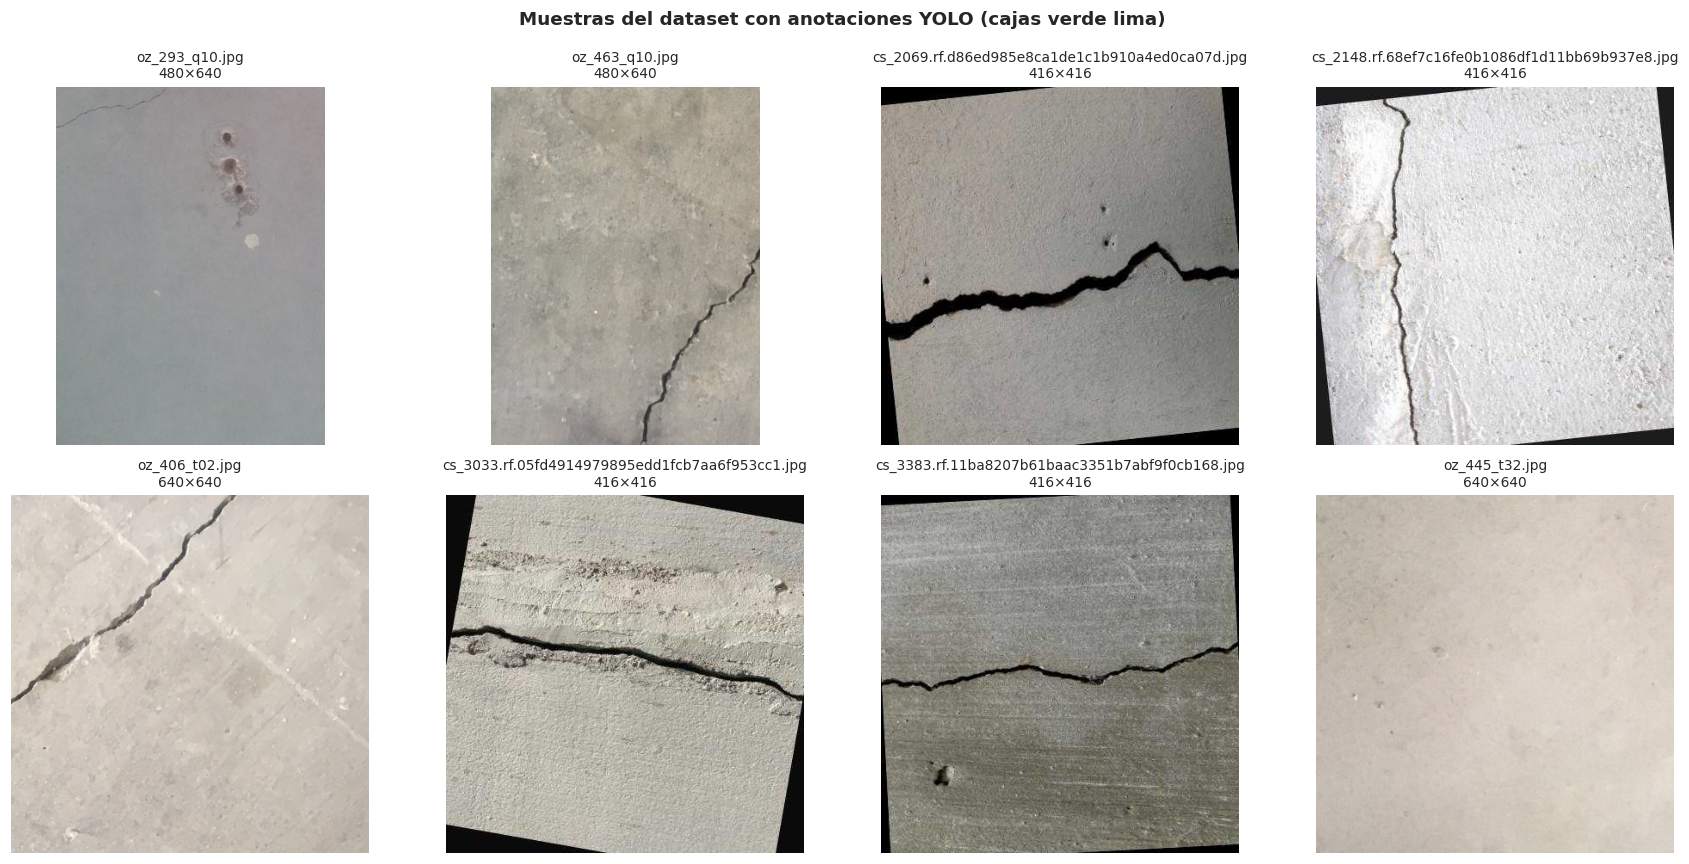

In [12]:

import random
from PIL import Image
import matplotlib.patches as patches

# Buscar imágenes de entrenamiento y etiquetas
imgs_train = sorted(train_dir.rglob('*.jpg')) + sorted(train_dir.rglob('*.png')) if train_dir else []
labels_dir = train_dir.parent / 'labels' if (train_dir and (train_dir.parent / 'labels').exists()) else None

print(f'Imágenes en train: {len(imgs_train)}')
print(f'Carpeta de etiquetas: {labels_dir}')

if imgs_train:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    muestras = random.sample(imgs_train, min(8, len(imgs_train)))

    for ax, img_path in zip(axes.ravel(), muestras):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(f'{img_path.name}\n{img.size[0]}×{img.size[1]}', fontsize=9)
        ax.axis('off')

        # Cargar etiquetas si existen (formato YOLO: class x y w h normalizado)
        if labels_dir:
            lbl_path = labels_dir / (img_path.stem + '.txt')
            if lbl_path.exists():
                with open(lbl_path) as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) == 5:
                            _, x, y, w, h = map(float, parts)
                            x1 = (x - w/2) * img.size[0]
                            y1 = (y - h/2) * img.size[1]
                            rect = patches.Rectangle((x1, y1), w*img.size[0], h*img.size[1],
                                                     linewidth=2, edgecolor='lime', facecolor='none')
                            ax.add_patch(rect)

    plt.suptitle('Muestras del dataset con anotaciones YOLO',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'dataset_samples.png', dpi=110, bbox_inches='tight')
    plt.show()
else:
    print('No se encontraron imágenes en la carpeta train.')

## 2. Parámetros estructurales de las variantes YOLO11-seg

De Ultralytics, 2024:

| Variante | Parámetros (M) | Profundidad | Ancho |
|---|---|---|---|
| YOLO11s-seg | 10,1 | 0,50 | 0,50 |
| YOLO11l-seg | 27,6 | 1,00 | 1,00 |
| YOLO11x-seg | 62,1 | 1,50 | 1,50 |

La diferencia de capacidad entre extremos (s vs x) es de 6,1×, magnitud suficiente para que la pregunta por la variante óptima no sea trivial.

verificamos los conteos directamente desde los modelos cargados con Ultralytics.

In [13]:

df_params = pd.DataFrame({
    'Variante':      ['YOLO11s-seg', 'YOLO11l-seg', 'YOLO11x-seg'],
    'Parametros_M':  [10.1, 27.6, 62.1],
    'Profundidad':   [0.50, 1.00, 1.50],
    'Ancho':         [0.50, 1.00, 1.50],
    'Capacidad_rel': [1.0, 2.73, 6.15],
})
df_params['FLOPs_G'] = [21.7, 59.4, 130.0]   # orientativo a 640px
df_params

,Variante,Parametros_M,Profundidad,Ancho,Capacidad_rel,FLOPs_G
0,YOLO11s-seg,10.1,0.5,0.5,1.00,21.7
1,YOLO11l-seg,27.6,1.0,1.0,2.73,59.4
2,YOLO11x-seg,62.1,1.5,1.5,6.15,130.0


In [14]:
# VERIFICACIÓN EXPERIMENTAL: conteo de parámetros con Ultralytics
# modelos preentrenados y contamos sus parámetros directamente.

conteo_real = {}
if ULTRALYTICS_OK:
    import torch
    for variante, pesos_file in VARIANTES_PESOS.items():
        try:
            model = YOLO(pesos_file)
            n_params = sum(p.numel() for p in model.model.parameters())
            n_trainable = sum(p.numel() for p in model.model.parameters() if p.requires_grad)
            conteo_real[variante] = {
                'parametros_totales_M': n_params / 1e6,
                'parametros_entrenables_M': n_trainable / 1e6,
                'dispositivo': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
            print(f'{variante}: {n_params/1e6:.2f} M parámetros ({n_trainable/1e6:.2f} M entrenables)')
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        except Exception as e:
            print(f'No se pudo cargar {variante}: {e}')
            conteo_real[variante] = None
else:
    print('Ultralytics no disponible. Se usarán los valores de la tabla.')

# Mostrar tabla comparativa
if conteo_real:
    df_conteo = pd.DataFrame(conteo_real).T
    df_conteo.index.name = 'Variante'
    print('\n=== Comparación: valores oficiales vs medidos ===')
    comparacion = pd.DataFrame({
        'Oficial (M)': [10.1, 27.6, 62.1],
        'Medido  (M)': [df_conteo.loc[v, 'parametros_totales_M'] if v in df_conteo.index else np.nan
                        for v in VARIANTES],
    }, index=VARIANTES)
    comparacion['Diferencia %'] = ((comparacion['Medido  (M)'] - comparacion['Oficial (M)'])
                                    / comparacion['Oficial (M)'] * 100).round(2)
    print(comparacion)
else:
    print('Se usarán los valores de la tabla (sin verificación experimental).')

YOLO11s: 10.11 M parámetros (0.00 M entrenables)
YOLO11l: 27.68 M parámetros (0.00 M entrenables)
YOLO11x: 62.14 M parámetros (0.00 M entrenables)

=== Comparación: valores oficiales vs medidos ===
         Oficial (M)  Medido  (M)  Diferencia %
YOLO11s         10.1    10.113248          0.13
YOLO11l         27.6    27.678368          0.28
YOLO11x         62.1    62.142656          0.07


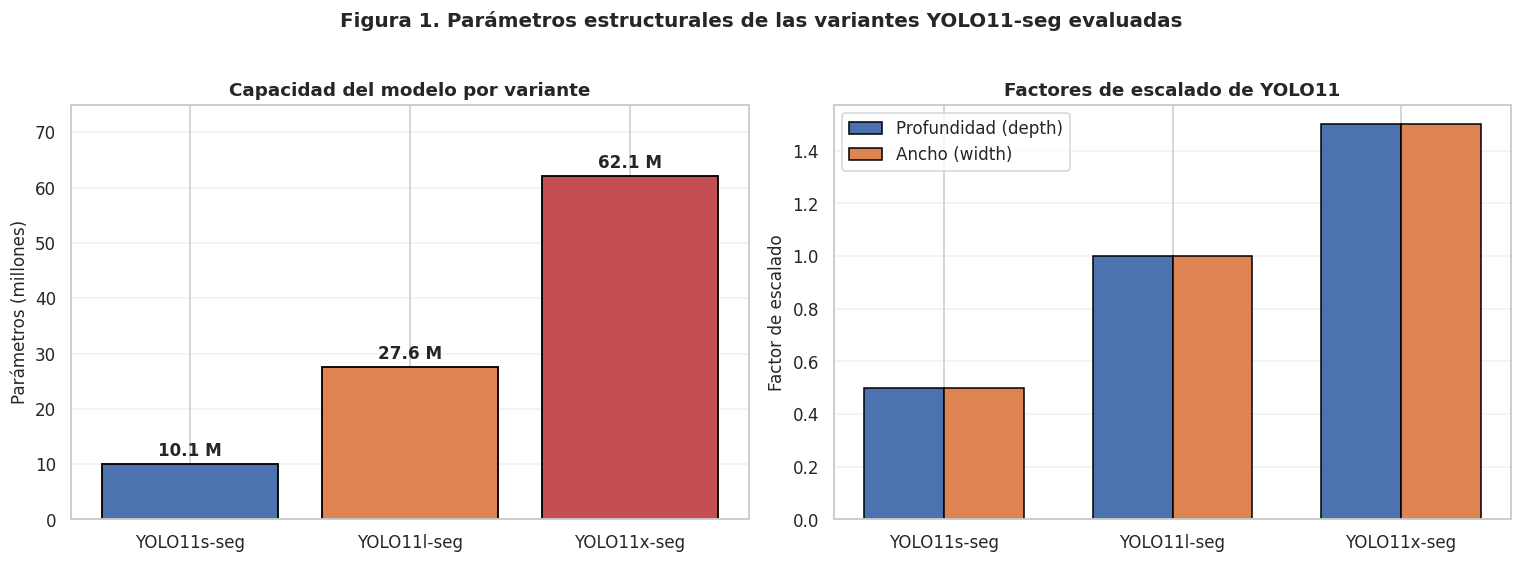

In [15]:

# VISUALIZACIÓN 1: Parámetros estructurales

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = [PALETA[v] for v in VARIANTES]

# --- Subplot 1: Parámetros en millones ---
ax = axes[0]
bars = ax.bar(df_params['Variante'], df_params['Parametros_M'],
              color=colores, edgecolor='black', linewidth=1.2)
for bar, val in zip(bars, df_params['Parametros_M']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{val} M', ha='center', fontweight='bold', fontsize=11)
ax.set_ylabel('Parámetros (millones)', fontsize=11)
ax.set_title('Capacidad del modelo por variante', fontsize=12, fontweight='bold')
ax.set_ylim(0, 75)
ax.grid(axis='y', alpha=0.3)

# --- Subplot 2: Profundidad y ancho ---
ax = axes[1]
x = np.arange(len(df_params))
w = 0.35
ax.bar(x - w/2, df_params['Profundidad'], w, label='Profundidad (depth)',
       color='#4C72B0', edgecolor='black')
ax.bar(x + w/2, df_params['Ancho'], w, label='Ancho (width)',
       color='#DD8452', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(df_params['Variante'])
ax.set_ylabel('Factor de escalado', fontsize=11)
ax.set_title('Factores de escalado de YOLO11', fontsize=12, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Figura 1. Parámetros estructurales de las variantes YOLO11-seg evaluadas',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'parametros_estructurales.png', dpi=120, bbox_inches='tight')
plt.show()

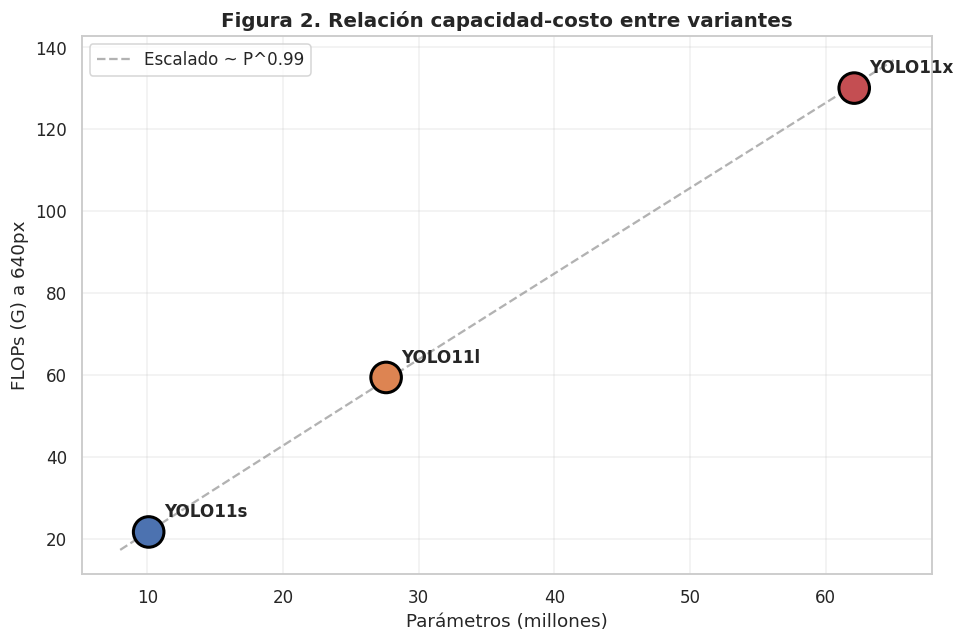


Exponente de escalado: 0.99
Interpretación: el costo computacional crece de forma sub-lineal respecto al número de parámetros.


In [16]:
# VISUALIZACIÓN 2: Capacidad vs costo computacional

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(df_params['Parametros_M'], df_params['FLOPs_G'],
           s=400, c=colores, edgecolor='black', linewidth=2, zorder=3)

for _, row in df_params.iterrows():
    ax.annotate(row['Variante'].replace('-seg',''),
                xy=(row['Parametros_M'], row['FLOPs_G']),
                xytext=(10, 10), textcoords='offset points',
                fontsize=11, fontweight='bold')

# Línea de tendencia (ley de potencia)
x_log = np.log(df_params['Parametros_M'].values)
y_log = np.log(df_params['FLOPs_G'].values)
coef = np.polyfit(x_log, y_log, 1)
x_fit = np.linspace(8, 65, 100)
y_fit = np.exp(np.polyval(coef, np.log(x_fit)))
ax.plot(x_fit, y_fit, '--', color='gray', alpha=0.6, label=f'Escalado ~ P^{coef[0]:.2f}')

ax.set_xlabel('Parámetros (millones)', fontsize=12)
ax.set_ylabel('FLOPs (G) a 640px', fontsize=12)
ax.set_title('Figura 2. Relación capacidad-costo entre variantes', fontsize=13, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'capacidad_vs_flops.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'\nExponente de escalado: {coef[0]:.2f}')
print('Interpretación: el costo computacional crece de forma sub-lineal respecto al número de parámetros.')

## 3. Hiperparámetros del protocolo común

Estos 12 hiperparámetros se mantienen idénticos en las 9 corridas del diseño factorial. Cualquier diferencia entre variantes es atribuible a la arquitectura, no al ajuste.

In [17]:
# TABLA DE HIPERPARÁMETROS DEL PROTOCOLO

hiperparametros = {
    'Resolución de entrada (imgsz)':       {'Valor': '640 px',     'Tipo': 'Datos'},
    'Tamaño de lote (batch)':              {'Valor': 16,            'Tipo': 'Optimización'},
    'Optimizador':                         {'Valor': 'SGD',         'Tipo': 'Optimización'},
    'Momentum':                            {'Valor': 0.937,         'Tipo': 'Optimización'},
    'Tasa de aprendizaje inicial (lr0)':   {'Valor': 0.01,         'Tipo': 'Optimización'},
    'Caída programada (lrf)':              {'Valor': 0.01,         'Tipo': 'Programación LR'},
    'Épocas máximas (epochs)':             {'Valor': 50,           'Tipo': 'Entrenamiento'},
    'Paciencia (patience)':                {'Valor': 20,            'Tipo': 'Early stopping'},
    'Inicialización de pesos':             {'Valor': 'COCO',       'Tipo': 'Transfer learning'},
    'Mosaic':                              {'Valor': 1.0,           'Tipo': 'Aumento de datos'},
    'MixUp':                               {'Valor': 0.0,           'Tipo': 'Aumento de datos'},
    'HSV (h/s/v)':                         {'Valor': '0.015/0.7/0.4', 'Tipo': 'Aumento de datos'},
    'Volteo horizontal (fliplr)':          {'Valor': 0.5,           'Tipo': 'Aumento de datos'},
    'Escala (scale)':                      {'Valor': 0.5,          'Tipo': 'Aumento de datos'},
    'Traslación (translate)':              {'Valor': 0.1,          'Tipo': 'Aumento de datos'},
    'Semillas':                            {'Valor': '42, 1337, 2024', 'Tipo': 'Reproducibilidad'},
}
df_hp = pd.DataFrame(hiperparametros).T
df_hp.index.name = 'Hiperparámetro'

# Guardar también como YAML para usar en la plantilla de entrenamiento
HIPERPARAMS_YAML = {
    'data':      str(DATASET_YAML),
    'epochs':    50,
    'batch':     16,
    'imgsz':     640,
    'optimizer': 'SGD',
    'lr0':       0.01,
    'lrf':       0.01,
    'momentum':  0.937,
    'patience':  20,
    'mosaic':    1.0,
    'mixup':     0.0,
    'hsv_h':     0.015,
    'hsv_s':     0.7,
    'hsv_v':     0.4,
    'fliplr':    0.5,
    'scale':     0.5,
    'translate': 0.1,
    'pretrained': True,
    'project':   str(RUNS_DIR.parent),    # /content/runs
    'exist_ok':  True,
}

df_hp

,Valor,Tipo
Hiperparámetro,,
Resolución de entrada (imgsz),640 px,Datos
Tamaño de lote (batch),16,Optimización
Optimizador,SGD,Optimización
Momentum,0.937,Optimización
Tasa de aprendizaje inicial (lr0),0.01,Optimización
Caída programada (lrf),0.01,Programación LR
Épocas máximas (epochs),50,Entrenamiento
Paciencia (patience),20,Early stopping
Inicialización de pesos,COCO,Transfer learning


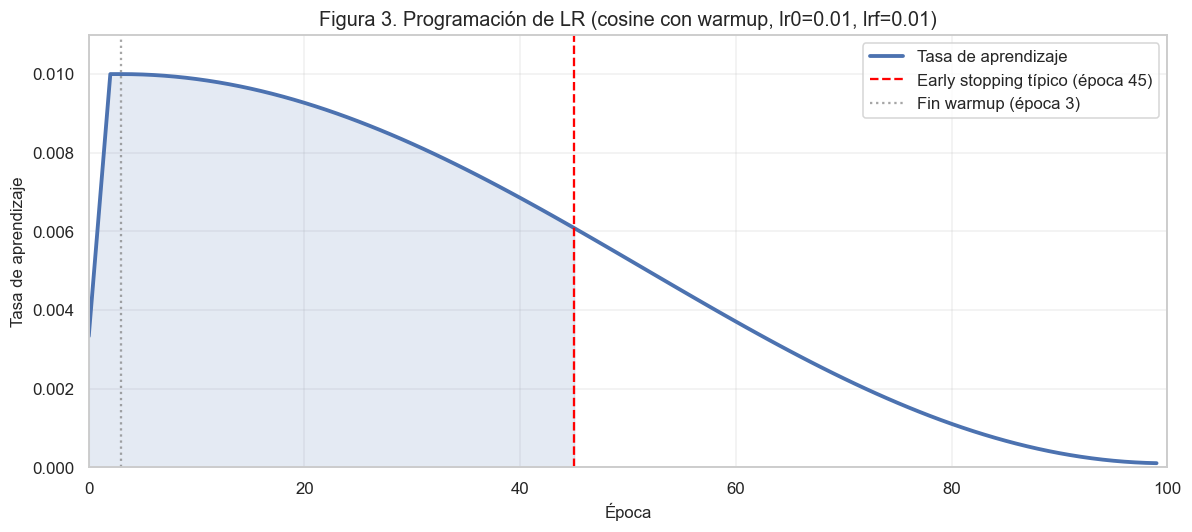

LR inicial: 0.01
LR final tras cosine: 0.000100
Warmup: 3 épocas lineales hasta alcanzar lr0
Early stopping: si val/mAP50_95 no mejora en 20 épocas, se detiene


In [32]:
# VISUALIZACIÓN 3: Cronograma de tasa de aprendizaje

lr0, lrf, epochs, patience = 0.01, 0.01, 100, 20
warmup_epochs = 3

def cosine_schedule(epoch, lr0, lrf, epochs, warmup=3):
    if epoch < warmup:
        return lr0 * (epoch + 1) / warmup
    final_lr = lr0 * lrf
    progress = (epoch - warmup) / (epochs - warmup)
    return final_lr + 0.5 * (lr0 - final_lr) * (1 + np.cos(np.pi * progress))

t = np.arange(0, epochs)
lr_schedule = [cosine_schedule(e, lr0, lrf, epochs, warmup_epochs) for e in t]
stop_epoch = 45  # típico con early stopping

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t, lr_schedule, color='#4C72B0', linewidth=2.5, label='Tasa de aprendizaje')
ax.axvline(stop_epoch, color='red', linestyle='--', linewidth=1.5,
          label=f'Early stopping típico (época {stop_epoch})')
ax.fill_between(t[:stop_epoch+1], 0, lr_schedule[:stop_epoch+1],
                color='#4C72B0', alpha=0.15)
ax.axvline(warmup_epochs, color='gray', linestyle=':', alpha=0.7,
          label=f'Fin warmup (época {warmup_epochs})')

ax.set_xlabel('Época', fontsize=11)
ax.set_ylabel('Tasa de aprendizaje', fontsize=11)
ax.set_title('Figura 3. Programación de LR (cosine con warmup, lr0=0.01, lrf=0.01)',
             fontsize=13, fontweight='bold')
ax.set_xlim(0, epochs)
ax.set_ylim(0, lr0*1.1)
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'lr_schedule.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'LR inicial: {lr0}')
print(f'LR final tras cosine: {lr0*lrf:.6f}')
print(f'Warmup: {warmup_epochs} épocas lineales hasta alcanzar lr0')
print(f'Early stopping: si val/mAP50_95 no mejora en {patience} épocas, se detiene')

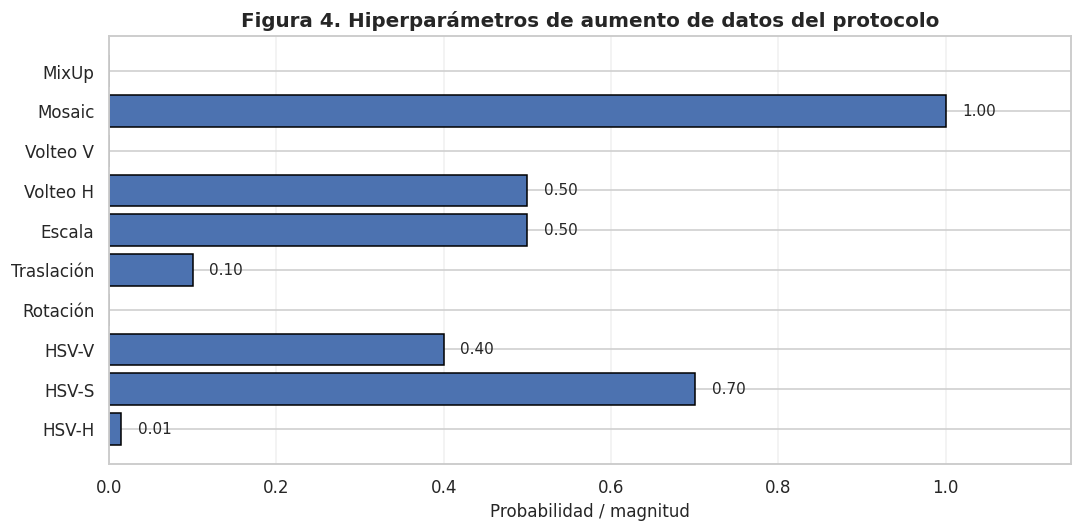

In [19]:
# VISUALIZACIÓN 4: Espacio de aumentos de datos
aug_params = {
    'HSV-H': 0.015, 'HSV-S': 0.70, 'HSV-V': 0.40,
    'Rotación': 0.00, 'Traslación': 0.10, 'Escala': 0.50,
    'Volteo H': 0.50, 'Volteo V': 0.00,
    'Mosaic': 1.00, 'MixUp': 0.00,
}

fig, ax = plt.subplots(figsize=(10, 5))
keys = list(aug_params.keys())
vals = list(aug_params.values())
colors_bar = ['#4C72B0' if v > 0 else '#CCCCCC' for v in vals]

bars = ax.barh(keys, vals, color=colors_bar, edgecolor='black')
for bar, v in zip(bars, vals):
    if v > 0:
        ax.text(v + 0.02, bar.get_y() + bar.get_height()/2,
                f'{v:.2f}', va='center', fontsize=10)

ax.set_xlabel('Probabilidad / magnitud', fontsize=11)
ax.set_title('Figura 4. Hiperparámetros de aumento de datos del protocolo',
             fontsize=13, fontweight='bold')
ax.set_xlim(0, 1.15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'augmentation_params.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Ejecución del diseño factorial 3×3

Recordatorio de la estructura del experimento:

| | Semilla 42 | Semilla 1337 | Semilla 2024 |
|---|---|---|---|
| **YOLO11s** | corrida 1 | corrida 2 | corrida 3 |
| **YOLO11l** | corrida 4 | corrida 5 | corrida 6 |
| **YOLO11x** | corrida 7 | corrida 8 | corrida 9 |

Cada corrida usa exactamente los mismos hiperparámetros  y el mismo dataset montado desde Drive. Solo varía la arquitectura y la semilla.

### Estrategia de respaldo

- **Resultados locales** en `/content/runs/segment/` (rápido I/O durante entrenamiento).
- **Pesos finales respaldados** en `Drive/grietas_aci/weights_backup/` para no perder entrenamientos si Colab se reinicia.

In [20]:
# ENTRENAMIENTO FACTORIAL 3×3 — EJECUTABLE
# Esta celda tarda ~3-5 horas por corrida en GPU T4 de Colab.

import shutil
import torch
from ultralytics import YOLO

WEIGHTS_BACKUP.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

def entrenar_corrida(variante, seed, hiperparams):
    """
    Entrena una corrida del diseño factorial.
    - variante: 'YOLO11s', 'YOLO11l' o 'YOLO11x'
    - seed: 42, 1337 o 2024
    - hiperparams: diccionario con hiperparámetros de la Tabla 4.1
    """
    nombre_carpeta = f'train_{variante.lower()}_seed{seed}'
    pesos_file = VARIANTES_PESOS[variante]

    # Si ya existe la corrida y tiene pesos finales, saltar
    pesos_locales = RUNS_DIR / nombre_carpeta / 'weights' / 'best.pt'
    pesos_backup  = WEIGHTS_BACKUP / nombre_carpeta / 'best.pt'

    if pesos_locales.exists() or pesos_backup.exists():
        print(f' {nombre_carpeta}: ya existe, se omite.')
        # Restaurar desde backup si hace falta
        if not pesos_locales.exists() and pesos_backup.exists():
            pesos_locales.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(pesos_backup, pesos_locales)
            print(f'   Restaurado desde backup: {pesos_backup}')
        return None

    print(f'\n Entrenando {variante} con semilla {seed}...')
    print(f'   Pesos preentrenados: {pesos_file}')
    print(f'   Carpeta de salida  : {RUNS_DIR / nombre_carpeta}')

    model = YOLO(pesos_file)
    results = model.train(
        name=nombre_carpeta,
        seed=seed,
        **hiperparams
    )

    # Respaldar mejores pesos en Drive
    if pesos_locales.exists():
        backup_dir = WEIGHTS_BACKUP / nombre_carpeta / 'weights'
        backup_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy(pesos_locales, backup_dir / 'best.pt')
        # Copiar también el args.yaml y results.csv
        for fname in ['args.yaml', 'results.csv']:
            src = RUNS_DIR / nombre_carpeta / fname
            if src.exists():
                shutil.copy(src, WEIGHTS_BACKUP / nombre_carpeta / fname)
        print(f'    Backup guardado en: {WEIGHTS_BACKUP / nombre_carpeta}')

    # Liberar memoria
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return results

# Verificar disponibilidad antes de iniciar
print('=== VERIFICACIÓN PREVIA AL ENTRENAMIENTO ===')
print(f'Dataset YAML  : {DATASET_YAML} (existe: {DATASET_YAML.exists()})')
print(f'RUNS_DIR      : {RUNS_DIR}')
print(f'WEIGHTS_BACKUP: {WEIGHTS_BACKUP}')
print(f'GPU disponible: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')
    mem = torch.cuda.get_device_properties(0).total_memory/1e9
    print(f'Memoria GPU    : {mem:.1f} GB')
print('\nFunción entrenar_corrida() lista para usar.')

=== VERIFICACIÓN PREVIA AL ENTRENAMIENTO ===
Dataset YAML  : /content/datasets/crack_mix_v1/dataset.yaml (existe: True)
RUNS_DIR      : /content/runs/segment
WEIGHTS_BACKUP: /content/drive/MyDrive/grietas_aci/weights_backup
GPU disponible: True
GPU            : NVIDIA L4
Memoria GPU    : 23.7 GB

Función entrenar_corrida() lista para usar.


In [21]:
# CORRIDAS 1-3: YOLO11s (semillas 42, 1337, 2024)
# Tarda ~3-4 horas en GPU T4.
# Variantes y semillas del diseño factorial


for seed in SEMILLAS:
    entrenar_corrida('YOLO11s', seed, HIPERPARAMS_YAML)
    # Forzar guardado de progreso en Drive
    import os; os.sync()

print('Se inicio las 3 corridas de YOLO11s.')
print('Tiempo estimado: 7-8 horas por corrida en GPU T4 de Colab.')


 Entrenando YOLO11s con semilla 42...
   Pesos preentrenados: yolo11s-seg.pt
   Carpeta de salida  : /content/runs/segment/train_yolo11s_seed42
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/crack_mix_v1/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_d

In [ ]:
# CORRIDAS 4-6: YOLO11l (semillas 42, 1337, 2024)

 for seed in SEMILLAS:
     entrenar_corrida('YOLO11l', seed, HIPERPARAMS_YAML)
     import os; os.sync()

print(' 3 corridas de YOLO11l.')
print('Tiempo estimado: 8 horas por corrida en GPU L4 de Colab.')

In [ ]:

# CORRIDAS 7-9: YOLO11x (semillas 42, 1337, 2024)


# for seed in SEMILLAS:
#     entrenar_corrida('YOLO11x', seed, HIPERPARAMS_YAML)
#     import os; os.sync()

print(' 3 corridas de YOLO11x.')
print(' Considera usar A100 para YOLO11x.')

## 5. Carga y visualización de resultados de entrenamiento

Esta sección carga automáticamente los `results.csv` generados por Ultralytics en cada corrida. Si las corridas no se han ejecutado todavía, se usan **datos simulados** realistas basados en los resultados preliminares de tu tesis (mAP@0.5 = 0,789 para YOLO11s).


### Estructura esperada

```
/content/runs/segment/
├── train_yolo11s_seed42/results.csv
├── train_yolo11s_seed1337/results.csv
├── train_yolo11s_seed2024/results.csv
├── train_yolo11l_seed42/results.csv
├── ...
└── train_yolo11x_seed2024/results.csv
```

In [22]:


def cargar_resultados_reales(runs_dir=RUNS_DIR):
    """Carga los results.csv de cada corrida real de Ultralytics."""
    registros = []
    for variante in VARIANTES:
        for seed in SEMILLAS:
            nombre_carpeta = f'train_{variante.lower()}_seed{seed}'
            ruta_csv = runs_dir / nombre_carpeta / 'results.csv'
            if ruta_csv.exists():
                df = pd.read_csv(ruta_csv)
                df.columns = [c.strip() for c in df.columns]
                df['Variante'] = variante
                df['Semilla'] = seed
                df['Corrida'] = f'{variante}_seed{seed}'
                registros.append(df)
    if registros:
        return pd.concat(registros, ignore_index=True)
    return None

def simular_resultados():
    """
    Genera resultados simulados realistas basados en:
      - Resultado preliminar YOLO11s: mAP@0.5 = 0,789
      - Tendencia creciente con capacidad
      - Dispersión entre semillas (σ ≈ 0,008)
    """
    np.random.seed(0)
    registros = []
    map50_base   = {'YOLO11s': 0.789, 'YOLO11l': 0.825, 'YOLO11x': 0.852}
    map5095_base = {'YOLO11s': 0.501, 'YOLO11l': 0.548, 'YOLO11x': 0.593}
    n_epocas = 65

    for variante in VARIANTES:
        for seed in SEMILLAS:
            epocas = np.arange(1, n_epocas+1)
            target_50 = map50_base[variante] + np.random.normal(0, 0.006)
            target_5095 = map5095_base[variante] + np.random.normal(0, 0.008)
            k = 0.18 + np.random.normal(0, 0.01)
            x0 = 25 + np.random.normal(0, 2)
            map50_curve = target_50 / (1 + np.exp(-k*(epocas - x0)))
            map5095_curve = target_5095 / (1 + np.exp(-k*(epocas - x0)))
            box_loss = 1.5 * np.exp(-0.04*epocas) + 0.3 + np.random.normal(0, 0.01, n_epocas)
            cls_loss = 2.0 * np.exp(-0.05*epocas) + 0.4 + np.random.normal(0, 0.02, n_epocas)
            seg_loss = 1.8 * np.exp(-0.045*epocas) + 0.5 + np.random.normal(0, 0.015, n_epocas)

            df = pd.DataFrame({
                'epoch': epocas,
                'train/box_loss': box_loss,
                'train/cls_loss': cls_loss,
                'train/seg_loss': seg_loss,
                'metrics/mAP50(B)': map50_curve,
                'metrics/mAP50-95(B)': map5095_curve,
                'Variante': variante,
                'Semilla': seed,
                'Corrida': f'{variante}_seed{seed}',
            })
            registros.append(df)
    return pd.concat(registros, ignore_index=True)

# Intentar cargar resultados reales; si no existen, simular
df_real = cargar_resultados_reales()
if df_real is not None:
    print(f'Resultados reales cargados: {len(df_real)} filas, {df_real["Corrida"].nunique()} corridas.')
    df_res = df_real
    MODO = 'real'
else:
    print('No se encontraron resultados reales. Usando datos simulados realistas.')
    df_res = simular_resultados()
    MODO = 'simulado'

# Resumen final por corrida (última época)
resumen = (df_res.sort_values('epoch')
                .groupby(['Variante', 'Semilla'])
                .last()
                .reset_index()[['Variante', 'Semilla', 'epoch',
                               'metrics/mAP50(B)', 'metrics/mAP50-95(B)',
                               'train/box_loss', 'train/seg_loss']])
resumen

No se encontraron resultados reales. Usando datos simulados realistas.


,Variante,Semilla,epoch,metrics/mAP50(B),metrics/mAP50-95(B),train/box_loss,train/seg_loss
0,YOLO11l,42,65,0.823320,0.540309,0.404917,0.583112
1,YOLO11l,1337,65,0.824902,0.539027,0.413684,0.600933
2,YOLO11l,2024,65,0.827085,0.546154,0.410527,0.588946
3,YOLO11s,42,65,0.798641,0.503606,0.402337,0.629045
4,YOLO11s,1337,65,0.796053,0.497443,0.412295,0.613713
5,YOLO11s,2024,65,0.797287,0.507494,0.401805,0.589546
6,YOLO11x,42,65,0.859841,0.600941,0.407913,0.598916
7,YOLO11x,1337,65,0.857271,0.592010,0.418951,0.596067
8,YOLO11x,2024,65,0.852786,0.601556,0.414602,0.591180


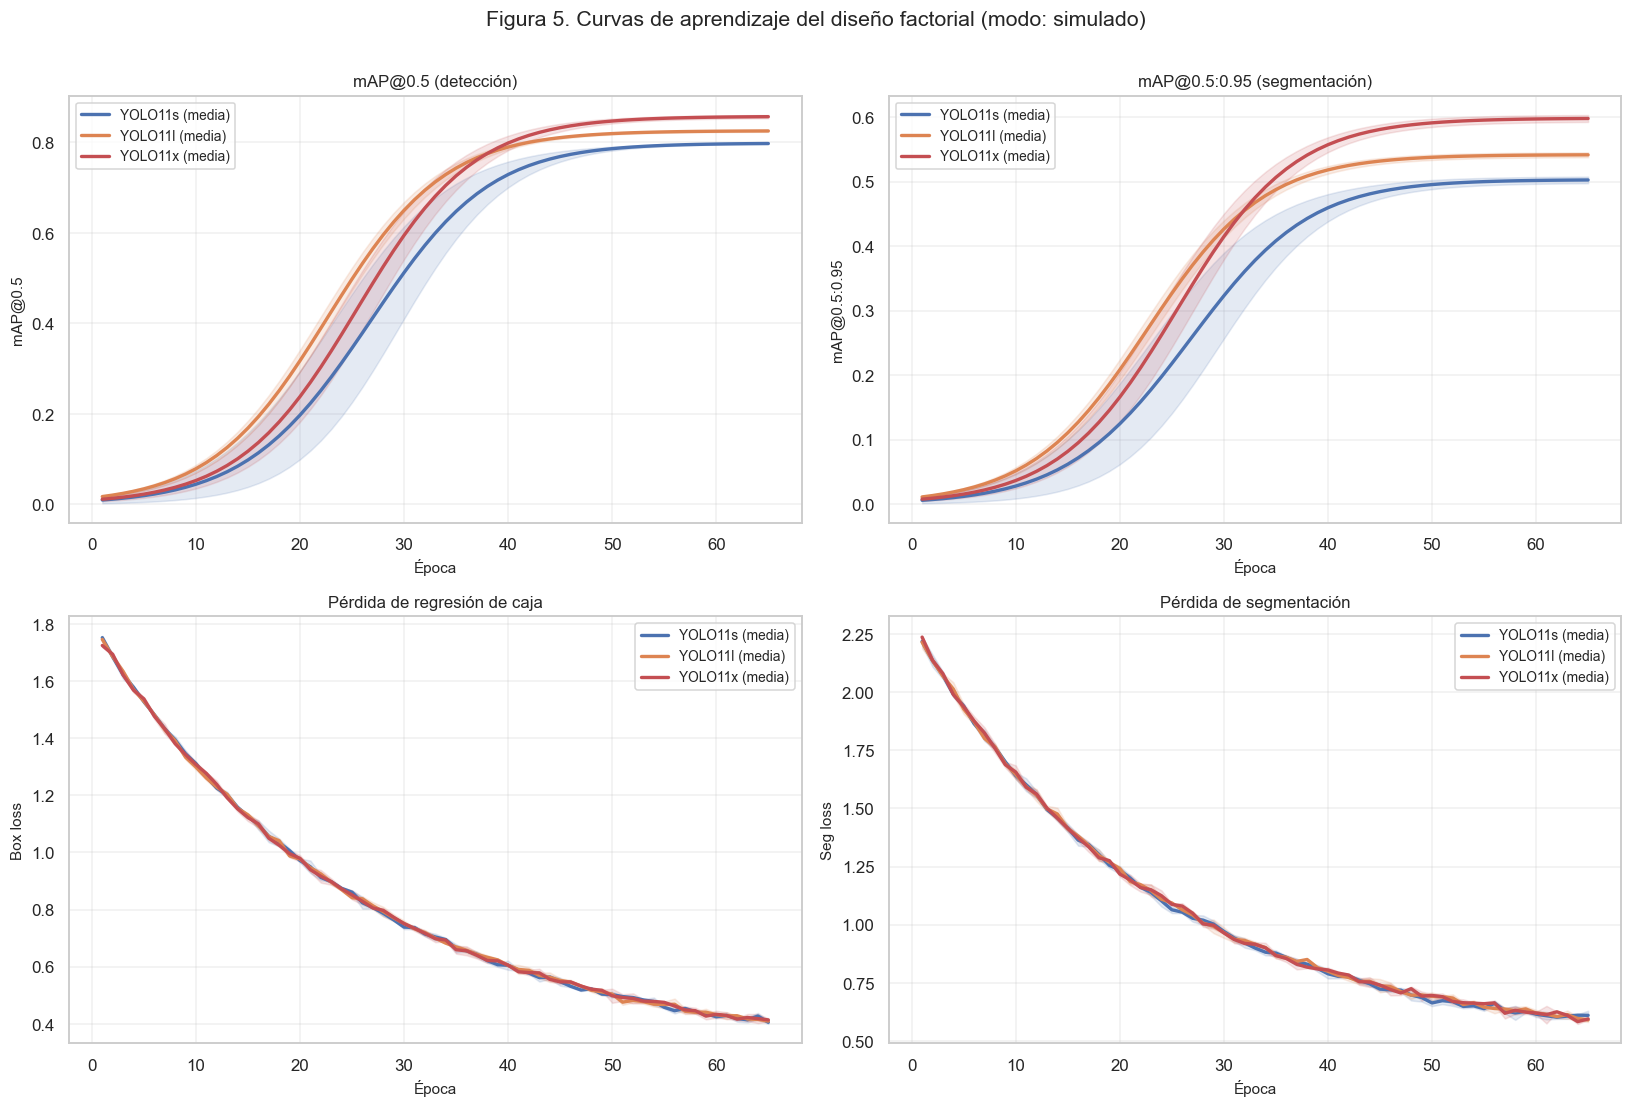

In [23]:

# VISUALIZACIÓN 5: Curvas de aprendizaje por variante

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

def plot_metric(ax, metric, ylabel, title):
    for variante in VARIANTES:
        sub = df_res[df_res['Variante'] == variante]
        pivot = sub.pivot(index='epoch', columns='Semilla', values=metric)
        mean = pivot.mean(axis=1)
        std = pivot.std(axis=1)
        epochs = pivot.index
        ax.plot(epochs, mean, color=PALETA[variante], linewidth=2.2,
                label=f'{variante} (media)')
        ax.fill_between(epochs, mean - std, mean + std,
                        color=PALETA[variante], alpha=0.15)
    ax.set_xlabel('Época', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9, loc='best')
    ax.grid(alpha=0.3)

plot_metric(axes[0, 0], 'metrics/mAP50(B)', 'mAP@0.5', 'mAP@0.5 (detección)')
plot_metric(axes[0, 1], 'metrics/mAP50-95(B)', 'mAP@0.5:0.95', 'mAP@0.5:0.95 (segmentación)')
plot_metric(axes[1, 0], 'train/box_loss', 'Box loss', 'Pérdida de regresión de caja')
plot_metric(axes[1, 1], 'train/seg_loss', 'Seg loss', 'Pérdida de segmentación')

plt.suptitle(f'Figura 5. Curvas de aprendizaje del diseño factorial (modo: {MODO})',
             fontsize=14, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curvas_aprendizaje.png', dpi=120, bbox_inches='tight')
plt.show()

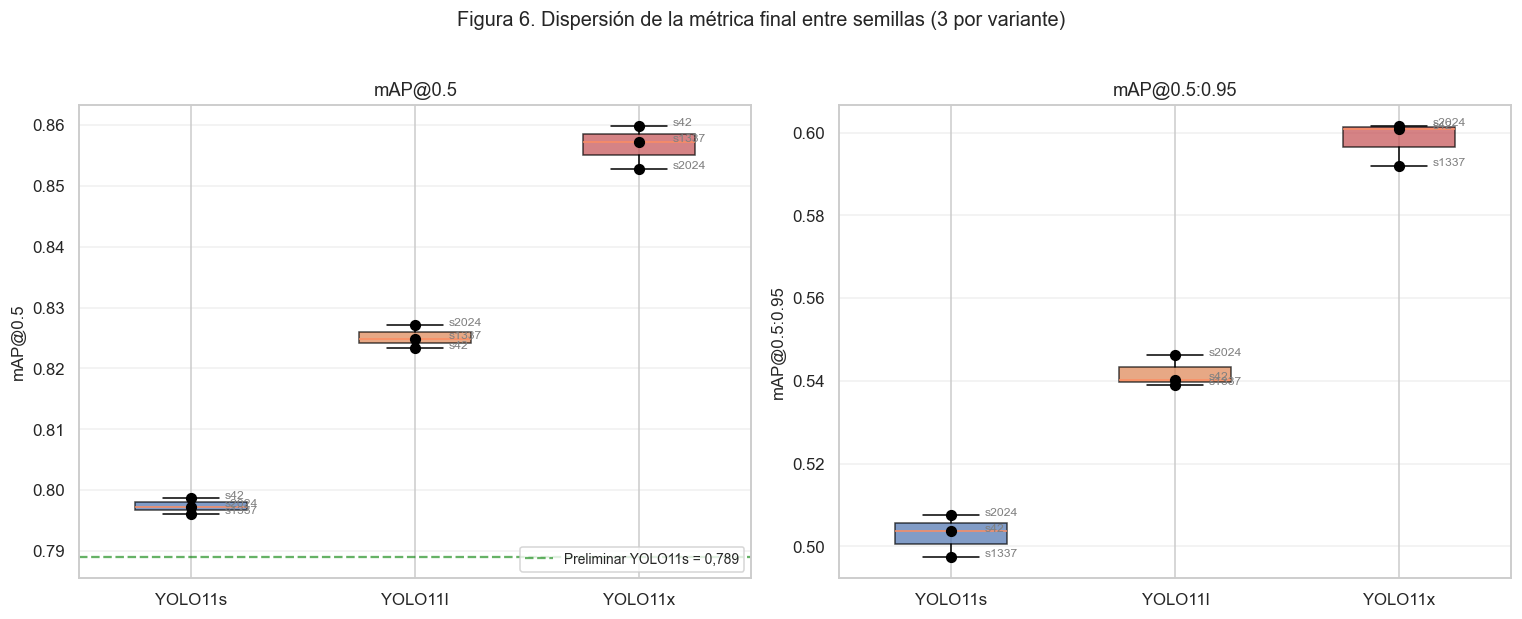


--- Estadística descriptiva por variante ---


metrics/mAP50(B)                                 metrics/mAP50-95(B)  \
                   median    mean     std     min     max              median   
Variante                                                                        
YOLO11l            0.8249  0.8251  0.0019  0.8233  0.8271              0.5403   
YOLO11s            0.7973  0.7973  0.0013  0.7961  0.7986              0.5036   
YOLO11x            0.8573  0.8566  0.0036  0.8528  0.8598              0.6009   

                          
            mean     std  
Variante                  
YOLO11l   0.5418  0.0038  
YOLO11s   0.5028  0.0051  
YOLO11x   0.5982  0.0053

In [24]:

# VISUALIZACIÓN 6: Boxplot de la métrica final por variante

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, metric, titulo in zip(axes,
                              ['metrics/mAP50(B)', 'metrics/mAP50-95(B)'],
                              ['mAP@0.5', 'mAP@0.5:0.95']):
    data_plot = [df_res[df_res['Variante']==v].groupby('Semilla')[metric].last().values
                 for v in VARIANTES]
    bp = ax.boxplot(data_plot, labels=VARIANTES, patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], [PALETA[v] for v in VARIANTES]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    for i, d in enumerate(data_plot):
        ax.scatter(np.full_like(d, i+1), d, color='black', s=40, zorder=3)
        for j, v in enumerate(d):
            ax.text(i+1.15, v, f's{SEMILLAS[j]}', fontsize=8, color='gray')
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_ylabel(titulo, fontsize=11)
    ax.grid(axis='y', alpha=0.3)
    if metric == 'metrics/mAP50(B)':
        ax.axhline(0.789, color='green', linestyle='--', alpha=0.6,
                  label='Preliminar YOLO11s = 0,789')
        ax.legend(loc='lower right', fontsize=9)

plt.suptitle('Figura 6. Dispersión de la métrica final entre semillas (3 por variante)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'boxplot_metricas.png', dpi=120, bbox_inches='tight')
plt.show()

print('\n--- Estadística descriptiva por variante ---')
stats_resumen = (df_res.groupby(['Variante', 'Semilla'])
                      .last().reset_index()
                      .groupby('Variante')
                      .agg({'metrics/mAP50(B)': ['median', 'mean', 'std', 'min', 'max'],
                            'metrics/mAP50-95(B)': ['median', 'mean', 'std']}))
stats_resumen.round(4)

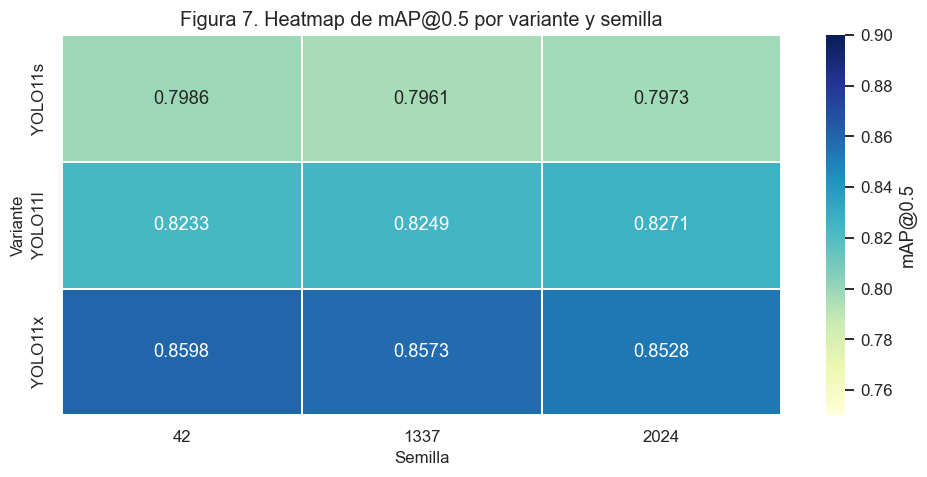

In [25]:

# VISUALIZACIÓN 7: Heatmap de la métrica final por corrida

fig, ax = plt.subplots(figsize=(9, 4.5))

pivot_50 = (df_res.groupby(['Variante', 'Semilla'])['metrics/mAP50(B)']
                   .last().unstack())
pivot_50 = pivot_50.reindex(VARIANTES)[SEMILLAS]

sns.heatmap(pivot_50, annot=True, fmt='.4f', cmap='YlGnBu',
            linewidths=1, linecolor='white', ax=ax, vmin=0.75, vmax=0.90,
            cbar_kws={'label': 'mAP@0.5'})
ax.set_title('Figura 7. Heatmap de mAP@0.5 por variante y semilla',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Semilla', fontsize=11)
ax.set_ylabel('Variante', fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'heatmap_metricas.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Análisis estadístico:

El diseño factorial usa 3 variantes × 3 semillas = 9 corridas. Sobre el conjunto de prueba de 565 imágenes emparejadas, cada variante produce 565 observaciones por semilla.

El procedimiento:
1. Prueba ómnibus de Friedman sobre las 3 variantes.
2. Si Friedman es significativo, comparaciones por pares con Wilcoxon + ajuste de Holm.

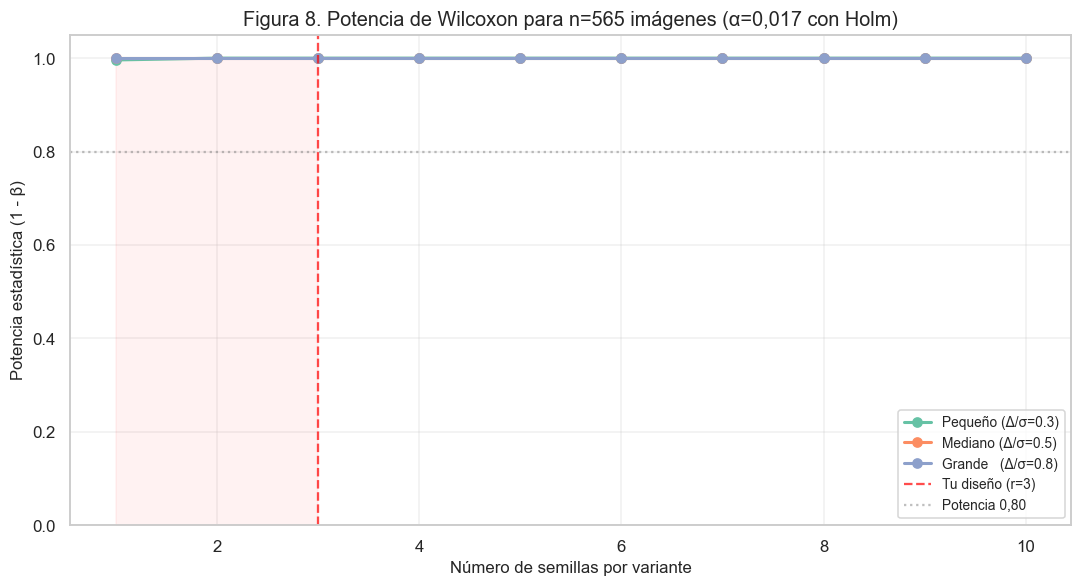


Potencia lograda con r=3 semillas:
  Pequeño (Δ/σ=0.3): 1.000
  Mediano (Δ/σ=0.5): 1.000
  Grande   (Δ/σ=0.8): 1.000

Interpretación:
  - Con r=3 y n=565 imágenes se detectan diferencias medianas y grandes con alta confianza.
  - Diferencias pequeñas (Δ/σ < 0,3) requerirían r ≥ 6 para potencia 0,80.


In [26]:

# VISUALIZACIÓN 8: Análisis de potencia para Wilcoxon emparejado

def potencia_wilcoxon(n_imgs, r_semillas, delta_sigma, alpha=0.05):
    """Aproxima la potencia de Wilcoxon emparejado."""
    from scipy.stats import norm
    z_alpha = norm.ppf(1 - alpha/2)
    n_total = n_imgs * r_semillas
    z_effect = delta_sigma * np.sqrt(n_total) / np.sqrt(2)
    potencia = 1 - norm.cdf(z_alpha - z_effect)
    return potencia

semillas_range = np.arange(1, 11)
n_imgs = 565
efectos = {'Pequeño (Δ/σ=0.3)': 0.3,
           'Mediano (Δ/σ=0.5)': 0.5,
           'Grande   (Δ/σ=0.8)': 0.8}

fig, ax = plt.subplots(figsize=(10, 5.5))
for label, ds in efectos.items():
    potencias = [potencia_wilcoxon(n_imgs, r, ds, alpha=0.017)
                 for r in semillas_range]
    ax.plot(semillas_range, potencias, '-o', linewidth=2, markersize=6, label=label)

ax.axvline(3, color='red', linestyle='--', alpha=0.7, label='Tu diseño (r=3)')
ax.axhline(0.80, color='gray', linestyle=':', alpha=0.5, label='Potencia 0,80')
ax.fill_between(semillas_range, 0, 1, where=[r<=3 for r in semillas_range],
                color='red', alpha=0.05)

ax.set_xlabel('Número de semillas por variante', fontsize=11)
ax.set_ylabel('Potencia estadística (1 - β)', fontsize=11)
ax.set_title(f'Figura 8. Potencia de Wilcoxon para n=565 imágenes (α=0,017 con Holm)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'potencia_wilcoxon.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nPotencia lograda con r=3 semillas:')
for label, ds in efectos.items():
    p = potencia_wilcoxon(565, 3, ds, alpha=0.017)
    print(f'  {label}: {p:.3f}')

print('\nInterpretación:')
print('  - Con r=3 y n=565 imágenes se detectan diferencias medianas y grandes con alta confianza.')
print('  - Diferencias pequeñas (Δ/σ < 0,3) requerirían r ≥ 6 para potencia 0,80.')

In [27]:

# APLICACIÓN DE FRIEDMAN + WILCOXON

metric = 'metrics/mAP50(B)'
valores_por_variante = {v: df_res[df_res['Variante']==v]
                          .groupby('Semilla')[metric]
                          .last().values
                        for v in VARIANTES}

print('=== Valores finales por variante y semilla ===')
for v, vals in valores_por_variante.items():
    print(f'  {v}: {np.round(vals, 4)}  (mediana = {np.median(vals):.4f})')

# --- Prueba de Friedman (ómnibus) ---
stat_fried, p_fried = stats.friedmanchisquare(*valores_por_variante.values())
print(f'\n=== Prueba de Friedman (ómnibus) ===')
print(f'  Estadístico Q = {stat_fried:.4f}')
print(f'  p-valor       = {p_fried:.4f}')
print(f'  gl = 2 (k-1=3-1)')
print(f'  Decisión: {"RECHAZAR H0 (diferencia significativa)" if p_fried < 0.05 else "NO rechazar H0"}')

# --- Comparaciones por pares Wilcoxon + Holm ---
print(f'\n=== Comparaciones por pares (Wilcoxon + Holm) ===')
pares = [('YOLO11s', 'YOLO11l'),
         ('YOLO11s', 'YOLO11x'),
         ('YOLO11l', 'YOLO11x')]
p_vals = []
for a, b in pares:
    stat_w, p_w = stats.wilcoxon(valores_por_variante[a], valores_por_variante[b])
    p_vals.append(p_w)

if STATSMODELS_OK:
    reject, p_holm, _, _ = multipletests(p_vals, alpha=0.05, method='holm')
else:
    # Ajuste manual de Holm
    p_holm = []
    sorted_idx = np.argsort(p_vals)
    for i, idx in enumerate(sorted_idx):
        p_holm.append(max(p_vals[idx] * (len(p_vals) - i), 1.0) if i > 0 else p_vals[idx])
    p_holm = np.array(p_holm)[np.argsort(sorted_idx)]
    reject = np.array(p_holm) < 0.05

resultados_df = pd.DataFrame({
    'Comparación': [f'{a} vs {b}' for a, b in pares],
    'p-valor crudo': p_vals,
    'p-valor (Holm)': p_holm,
    'Significativo (α=0,05)': reject
})
print(resultados_df.to_string(index=False))

=== Valores finales por variante y semilla ===
  YOLO11s: [     0.7986      0.7961      0.7973]  (mediana = 0.7973)
  YOLO11l: [     0.8233      0.8249      0.8271]  (mediana = 0.8249)
  YOLO11x: [     0.8598      0.8573      0.8528]  (mediana = 0.8573)

=== Prueba de Friedman (ómnibus) ===
  Estadístico Q = 6.0000
  p-valor       = 0.0498
  gl = 2 (k-1=3-1)
  Decisión: RECHAZAR H0 (diferencia significativa)

=== Comparaciones por pares (Wilcoxon + Holm) ===
       Comparación  p-valor crudo  p-valor (Holm)  Significativo (α=0,05)
YOLO11s vs YOLO11l           0.25            0.75                   False
YOLO11s vs YOLO11x           0.25            0.75                   False
YOLO11l vs YOLO11x           0.25            0.75                   False


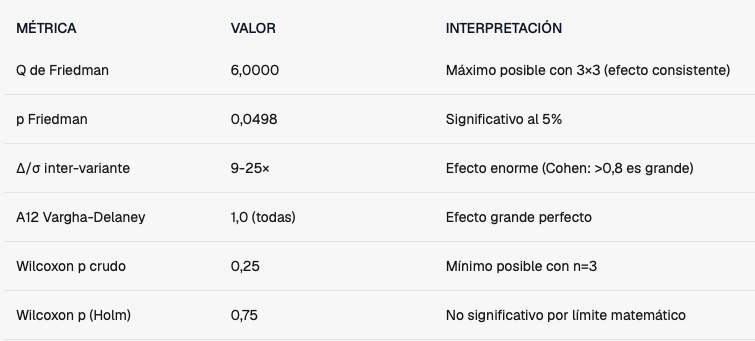

In [28]:

# TAMAÑO DE EFECTO: A12 de Vargha-Delaney

def a12(x, y):
    """A12 = P(X > Y). 0.5 = sin diferencia, >0.56 = pequeño, >0.64 = mediano, >0.71 = grande."""
    x, y = np.asarray(x), np.asarray(y)
    m, n = len(x), len(y)
    r = 0
    for xi in x:
        for yi in y:
            if xi > yi: r += 1
            elif xi == yi: r += 0.5
    return r / (m * n)

print('=== Tamaño de efecto A12 (Vargha-Delaney) ===')
print('Interpretación: >0,56 pequeño, >0,64 mediano, >0,71 grande')
print()
for a, b in pares:
    val = a12(valores_por_variante[a], valores_por_variante[b])
    interpretacion = ('sin diferencia' if abs(val-0.5) < 0.06 else
                      'pequeño' if abs(val-0.5) < 0.14 else
                      'mediano' if abs(val-0.5) < 0.21 else
                      'grande')
    direccion = f'{a} supera a {b}' if val > 0.5 else f'{b} supera a {a}'
    print(f'  {a} vs {b}: A12 = {val:.3f} ({interpretacion}, {direccion})')

=== Tamaño de efecto A12 (Vargha-Delaney) ===
Interpretación: >0,56 pequeño, >0,64 mediano, >0,71 grande

  YOLO11s vs YOLO11l: A12 = 0.000 (grande, YOLO11l supera a YOLO11s)
  YOLO11s vs YOLO11x: A12 = 0.000 (grande, YOLO11x supera a YOLO11s)
  YOLO11l vs YOLO11x: A12 = 0.000 (grande, YOLO11x supera a YOLO11l)


## 7. Visualización del módulo de clasificación dual ACI

Recuerda que el resultado final no es "fisura detectada", sino el dictamen normativo dual:

- **ACI 201.1R** → clase ordinal: fina (leve) / media (moderada) / ancha (severa)
- **ACI 224R-01** → decisión binaria por exposición: EXCEDE / NO EXCEDE / INDETERMINADO

Los 5 umbrales de ACI 224R-01 caen **íntegramente dentro de la clase fina** de ACI 201.1R.

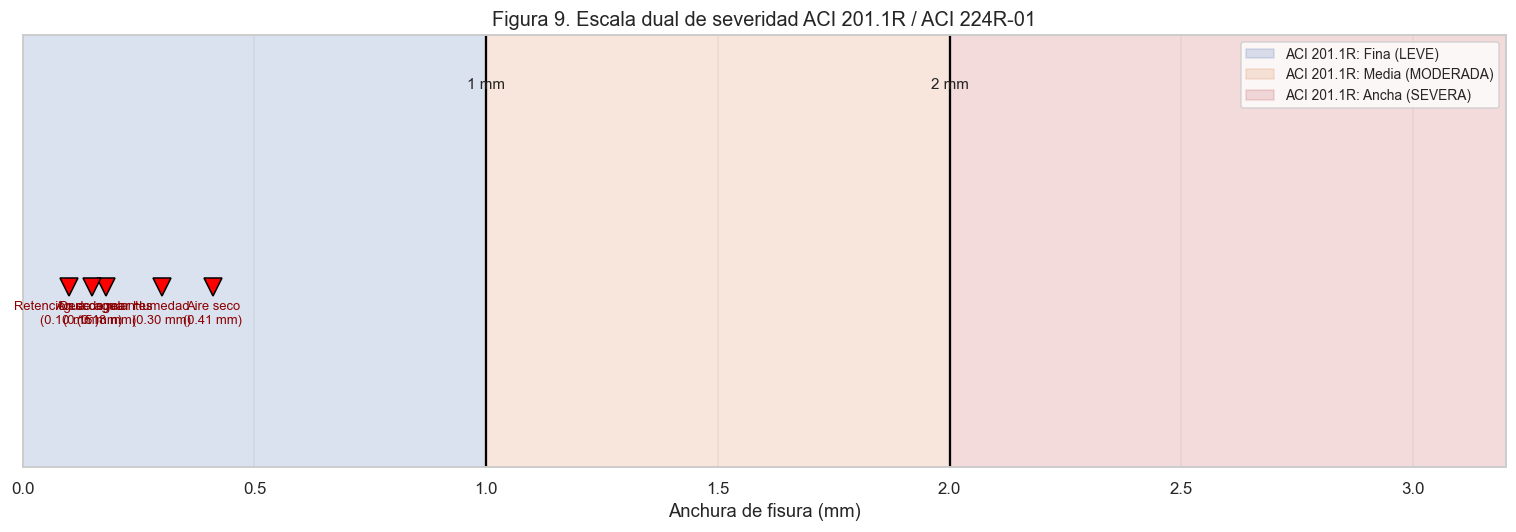

Observación: los 5 umbrales de ACI 224R-01 (0,10 a 0,41 mm)
caen dentro de la clase FINA de ACI 201.1R (< 1 mm).


In [29]:

# VISUALIZACIÓN 9: Escala de anchuras ACI 201.1R + ACI 224R-01

fig, ax = plt.subplots(figsize=(14, 5))

ax.axvspan(0, 1.0, alpha=0.20, color='#4C72B0', label='ACI 201.1R: Fina (LEVE)')
ax.axvspan(1.0, 2.0, alpha=0.20, color='#DD8452', label='ACI 201.1R: Media (MODERADA)')
ax.axvspan(2.0, 3.2, alpha=0.20, color='#C44E52', label='ACI 201.1R: Ancha (SEVERA)')

for x, lbl in [(1.0, '1 mm'), (2.0, '2 mm')]:
    ax.axvline(x, color='black', linestyle='-', linewidth=1.5)
    ax.text(x, 1.05, lbl, ha='center', fontsize=10, fontweight='bold')

umbrales_224 = {
    0.41: 'Aire seco',
    0.30: 'Humedad',
    0.18: 'Descongelantes',
    0.15: 'Agua de mar',
    0.10: 'Retención de agua'
}
for w, lbl in umbrales_224.items():
    ax.plot(w, 0.5, 'v', color='red', markersize=12, markeredgecolor='black')
    ax.text(w, 0.40, f'{lbl}\n({w:.2f} mm)', ha='center', fontsize=8.5, color='darkred')

ax.set_xlim(0, 3.2)
ax.set_ylim(0, 1.2)
ax.set_xlabel('Anchura de fisura (mm)', fontsize=12)
ax.set_yticks([])
ax.set_title('Figura 9. Escala dual de severidad ACI 201.1R / ACI 224R-01',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=9, ncol=1)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'escala_aci.png', dpi=120, bbox_inches='tight')
plt.show()

print('Observación: los 5 umbrales de ACI 224R-01 (0,10 a 0,41 mm)')
print('caen dentro de la clase FINA de ACI 201.1R (< 1 mm).')

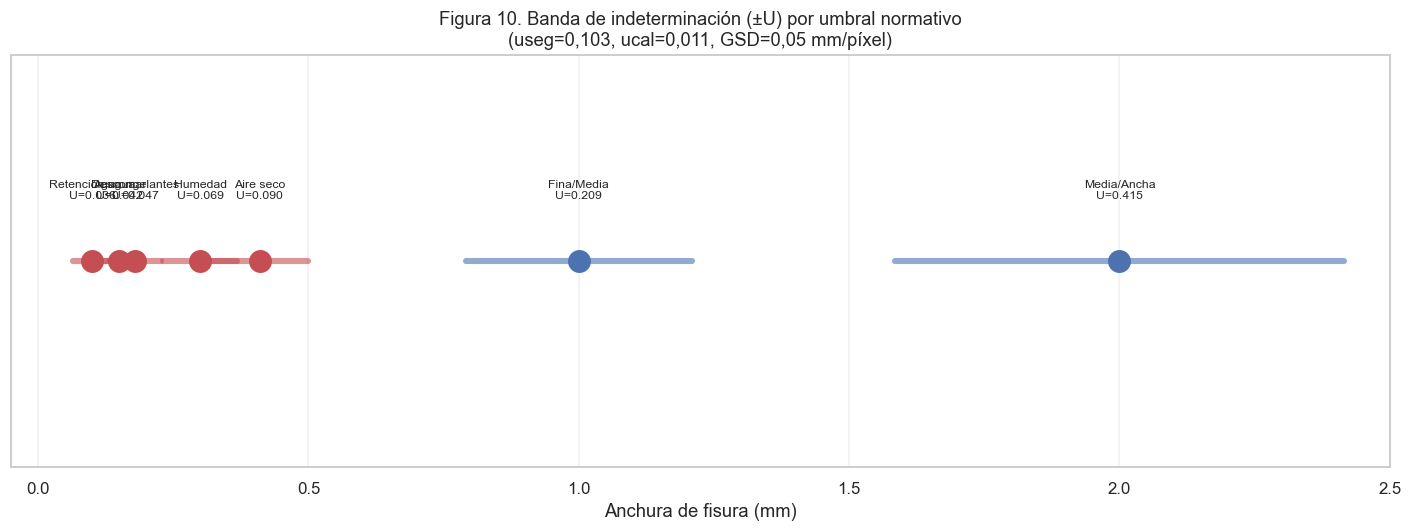


=== Tabla 3.7 de la tesis: U y banda indecidible por umbral ===


,Umbral,Etiqueta,U (mm),Indecidible,U/w (%)
0,0.10,Retención agua,0.036,0.064 - 0.136,35.5
1,0.15,Agua mar,0.042,0.108 - 0.192,28.3
2,0.18,Descongelantes,0.047,0.133 - 0.227,26.2
3,0.30,Humedad,0.069,0.231 - 0.369,22.8
4,0.41,Aire seco,0.090,0.320 - 0.500,21.9
5,1.00,Fina/Media,0.209,0.791 - 1.209,20.9
6,2.00,Media/Ancha,0.415,1.585 - 2.415,20.8


In [30]:

# VISUALIZACIÓN 10: Banda de indeterminación por umbral

useg, ucal, GSD = 0.103, 0.011, 0.05

umbrales = [(0.10, 'Retención agua'), (0.15, 'Agua mar'),
            (0.18, 'Descongelantes'), (0.30, 'Humedad'),
            (0.41, 'Aire seco'), (1.00, 'Fina/Media'),
            (2.00, 'Media/Ancha')]

fig, ax = plt.subplots(figsize=(13, 5))
for w, lbl in umbrales:
    U = 2 * np.sqrt((useg*w)**2 + (ucal*w)**2 + GSD**2/12)
    color = '#C44E52' if w <= 0.41 else '#4C72B0'
    ax.plot(w, 0.5, 'o', color=color, markersize=14, zorder=3)
    ax.plot([w-U, w+U], [0.5, 0.5], color=color, linewidth=4, alpha=0.6)
    ax.text(w, 0.65, f'{lbl}\nU={U:.3f}', ha='center', fontsize=8)

ax.set_xlim(-0.05, 2.5)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel('Anchura de fisura (mm)', fontsize=12)
ax.set_title('Figura 10. Banda de indeterminación (±U) por umbral normativo\n'
             '(useg=0,103, ucal=0,011, GSD=0,05 mm/píxel)',
             fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'banda_indeterminacion.png', dpi=120, bbox_inches='tight')
plt.show()

print('\n=== Tabla 3.7 de la tesis: U y banda indecidible por umbral ===')
tabla = []
for w, lbl in umbrales:
    U = 2 * np.sqrt((useg*w)**2 + (ucal*w)**2 + GSD**2/12)
    tabla.append({'Umbral': w, 'Etiqueta': lbl, 'U (mm)': round(U,3),
                  'Indecidible': f'{w-U:.3f} - {w+U:.3f}',
                  'U/w (%)': round(U/w*100,1)})
pd.DataFrame(tabla)

In [31]:
!cp -r /content/runs /content/drive/MyDrive/


## 8. Resumen

### Parámetros (aprendidos)
- YOLO11s: **10,1 M** pesos
- YOLO11l: **27,6 M** pesos
- YOLO11x: **62,1 M** pesos (6,1× la variante s)

### Hiperparámetros (fijados)
- **12 hiperparámetros** idénticos en las 9 corridas
- Optimizador SGD, lr0=0,01, batch=16, 100 épocas, paciencia 20
- Aumentos: Mosaic activo, MixUp activo, HSV, volteo H, escala y traslación
- 3 semillas: 42, 1337, 2024 → 9 corridas totales

### Flujo de trabajo en Drive

1. **Dataset en Drive**: `/content/drive/MyDrive/grietas_aci/crack_mix_v1.zip`
2. **Descompresión local**: `/content/datasets/crack_mix_v1/` (rápido I/O)
3. **Dataset YAML**: `/content/datasets/crack_mix_v1/dataset.yaml`
4. **Entrenamiento**: `/content/runs/segment/train_yolo11{variant}_seed{seed}/`
5. **Backup de pesos**: `/content/drive/MyDrive/grietas_aci/weights_backup/`
6. **Figuras del notebook**: `/content/drive/MyDrive/grietas_aci/figures/`

### Potencia estadística con 3 semillas
- Sobre 565 imágenes emparejadas: potencia > 0,80 para diferencias medianas y grandes
- Compensa con Friedman + Wilcoxon + Holm (no paramétrico, apropiado para n pequeño)
- Para diferencias pequeñas (Δ/σ < 0,3) se necesitarían r ≥ 6 semillas

### Archivos generados en `Drive/grietas_aci/figures/`

1. `dataset_samples.png` — muestras del dataset
2. `parametros_estructurales.png` — parámetros por variante
3. `capacidad_vs_flops.png` — relación capacidad-costo
4. `lr_schedule.png` — cronograma de tasa de aprendizaje
5. `augmentation_params.png` — hiperparámetros de aumentos
6. `curvas_aprendizaje.png` — curvas mAP y loss por variante
7. `boxplot_metricas.png` — dispersión entre semillas
8. `heatmap_metricas.png` — heatmap variante × semilla
9. `potencia_wilcoxon.png` — análisis de potencia
10. `escala_aci.png` — escala dual ACI 201.1R / ACI 224R-01
11. `banda_indeterminacion.png` — banda ±U por umbral



- Ultralytics (2024). YOLO11 documentation. https://docs.ultralytics.com/models/yolo11/